# MNIST 脉冲编码对照

Section 2 · Part 2 · Task 1：用同一张图片比较 Rate、Latency、Phase、Rank-order 和 Population。这里只生成输入脉冲，不训练分类网络。

先在项目根目录运行 `uv sync --locked --extra cpu` 和 `uv run --locked --extra cpu python mnist/prepare_data.py`，然后依次执行本 Notebook。图像使用 [0, 1] 的原始像素强度；为便于比较，这里的五种编码都将黑色背景设为不发放。


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

root = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "mnist" / "encoding.py").is_file()
)
sys.path.insert(0, str(root / "mnist"))

In [2]:
from encoding import encode_input

## 一、编码方式

基本原理是：**把像素亮度转换为神经元的脉冲活动，用脉冲的某种特征携带亮度信息。**

设像素强度为 $x_i\in[0,1]$，时间步为 $k=0,\ldots,T-1$，$s_i[k]\in\{0,1\}$ 表示是否发放。以下公式用于 $x_i>0$；黑色背景统一不发放。

| 编码 | 用什么表示亮度 | 直观理解 | 公式／规则 |
|---|---|---|---|
| Rate | 发放频率 | 越亮，单位时间内脉冲越多 | $s_i[k]\sim\mathrm{Bernoulli}(x_i)$，各步独立采样 |
| Latency | 首次发放时间 | 越亮，第一次脉冲越早 | $t_i=\operatorname{round}((1-x_i)(T-1))$，仅在 $k=t_i$ 发放 |
| Phase | 周期内的发放相位 | 越亮，每个周期中发放越早 | $\phi_i=\operatorname{round}((1-x_i)(P-1))$，在 $k\bmod P=\phi_i$ 发放 |
| Rank-order | 神经元之间的发放顺序 | 亮像素排在暗像素之前 | $t_i=\lfloor T r_i/N\rfloor$，仅在 $k=t_i$ 发放 |
| Population | 一组神经元的活动模式 | 不同亮度激活不同偏好的神经元 | $p_{ij}=\exp[-(x_i-\mu_j)^2/(2\sigma^2)]$，$s_{ij}[k]\sim\mathrm{Bernoulli}(p_{ij})$，独立采样 |

- Phase：周期 $P=20$。
- Rank-order：$r_i$ 为严格亮于像素 $i$ 的非黑色像素数，$N$ 为非黑色像素总数；相同亮度同时发放，有限时间步也可能使不同排名落在同一步。
- Population：每像素 $K=3$ 个神经元，$\mu_j\in\{0,0.5,1\}$，$\sigma=0.25$；其余编码每像素对应一个输入神经元。

Rate、Latency 为指定编码，Phase、Rank-order、Population 为自选编码。这里未指定每步的实际时长，因此下方报告每神经元每步的平均脉冲数，不称为 Hz。


参考：[Diehl & Cook（2015）：MNIST 输入发放率](https://www.frontiersin.org/journals/computational-neuroscience/articles/10.3389/fncom.2015.00099/full)；[Comsa 等（2021）：时序与首次发放](https://www.frontiersin.org/journals/neuroscience/articles/10.3389/fnins.2021.712667/full)；[Chen 等（2021）：脉冲相位](https://doi.org/10.1609/aaai.v35i8.16870)；[Rank-order 编码示例](https://pmc.ncbi.nlm.nih.gov/articles/PMC9047717/)；[Population 与高斯感受野](https://doi.org/10.3389/fncom.2023.1250908)。上述是便于比较的简化编码，不是对这些论文完整模型的复现。


## 二、实验要求

### 1. 原理与公式

三类编码的原理和公式见上文。


### 2. 对同一张 MNIST 图像编码

选择测试集中的一张图片，对其分别生成五种输入脉冲。


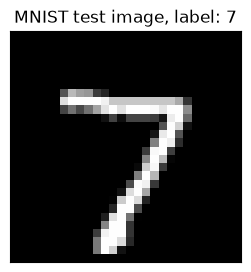

In [3]:
dataset = MNIST(
    root / "mnist" / "data", train=False, download=False, transform=ToTensor()
)
image_tensor, label = dataset[0]
image = image_tensor.squeeze(0).numpy()
images = image_tensor.unsqueeze(0)
fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(image, cmap="gray", vmin=0, vmax=1)
ax.set(title=f"MNIST test image, label: {label}", xticks=[], yticks=[])
plt.show()

In [4]:
steps, period, seed = 100, 20, 42
population_size = 3
encoded = {
    "Rate": encode_input(
        images, steps, "rate", generator=torch.Generator().manual_seed(seed)
    ),
    "Latency": encode_input(images, steps, "latency"),
    "Phase": encode_input(images, steps, "phase", period=period),
    "Rank-order": encode_input(images, steps, "rank_order"),
    "Population": encode_input(
        images,
        steps,
        "population",
        population_size=population_size,
        generator=torch.Generator().manual_seed(seed),
    ),
}
# [批次, 通道, 高, 宽, 时间] 转为 [时间, 输入神经元]。
trains = {
    name: value[0].permute(3, 0, 1, 2).reshape(steps, -1).numpy().astype(bool)
    for name, value in encoded.items()
}

### 3. 输入脉冲 Raster

横轴是时间步，纵轴是展平后的输入神经元编号，每个点是一枚脉冲。前四种有 784 个神经元；Population 每个像素有 3 个神经元，共 2352 个，因此它的纵轴范围不同。Population 编号按通道分组，每组 784 个像素。


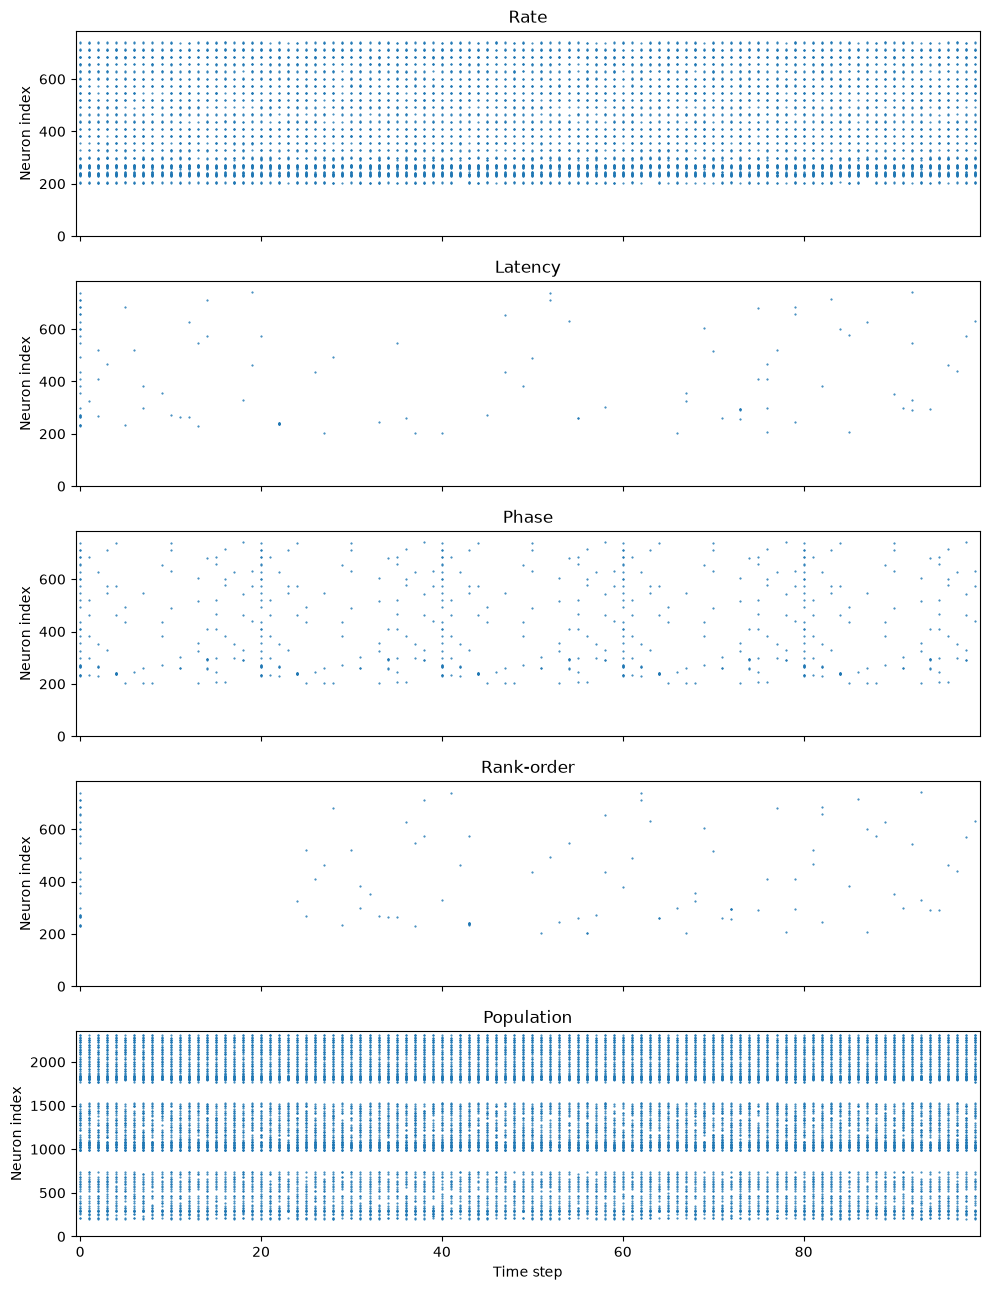

In [5]:
fig, axes = plt.subplots(len(trains), 1, figsize=(10, 13), sharex=True)
for ax, (name, spikes) in zip(axes, trains.items(), strict=True):
    time, neuron = np.nonzero(spikes)
    ax.scatter(time, neuron, s=1, marker=".")
    ax.set(
        title=name,
        ylabel="Neuron index",
        xlim=(-0.5, steps - 0.5),
        ylim=(-0.5, spikes.shape[1] - 0.5),
    )
axes[-1].set_xlabel("Time step")
fig.tight_layout()
plt.show()

### 4. 脉冲数量、稀疏性与时间分布

脉冲占比为 `脉冲总数 / (输入神经元数 × 时间步数)`，稀疏性为 `1 - 脉冲占比`；均包含未发放的背景。Population 的神经元数是其他方式的 3 倍，应同时看总数和每神经元的占比。下图统计每一步的输入脉冲数；Rate 和 Population 固定随机种子，但仍只是一次采样。


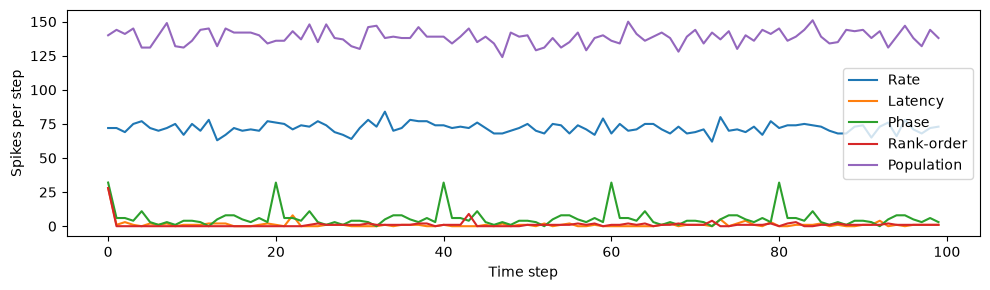

Encoding      Neurons   Spikes  Spike fraction   Sparsity  Active neurons
Rate              784     7207          0.0919     0.9081             114
Latency           784      116          0.0015     0.9985             116
Phase             784      580          0.0074     0.9926             116
Rank-order        784      116          0.0015     0.9985             116
Population       2352    13877          0.0590     0.9410             277


In [6]:
print(
    f"{'Encoding':<12} {'Neurons':>8} {'Spikes':>8} "
    f"{'Spike fraction':>15} {'Sparsity':>10} {'Active neurons':>15}"
)
for name, spikes in trains.items():
    count = int(spikes.sum())
    fraction = count / spikes.size
    active = int(spikes.any(axis=0).sum())
    print(
        f"{name:<12} {spikes.shape[1]:>8} {count:>8} "
        f"{fraction:>15.4f} {1 - fraction:>10.4f} {active:>15}"
    )
fig, ax = plt.subplots(figsize=(10, 3))
for name, spikes in trains.items():
    ax.plot(np.arange(steps), spikes.sum(axis=1), label=name)
ax.set(xlabel="Time step", ylabel="Spikes per step")
ax.legend()
fig.tight_layout()
plt.show()

#### 这张图片的结果

下面的分析根据当前输入图片、时间步与随机种子计算；不要把一次采样或一张图片的结果推广为分类性能。


In [7]:
latency, rank = trains["Latency"], trains["Rank-order"]
active = latency.any(axis=0) & rank.any(axis=0)
different_times = np.count_nonzero(
    latency.argmax(axis=0)[active] != rank.argmax(axis=0)[active]
)
print(
    f"原图非黑色像素：{np.count_nonzero(image)}；"
    f"Latency / Rank-order 分别发放 {latency.sum()} / {rank.sum()} 次，"
    f"其中 {different_times} 个像素的发放时间不同。"
)
print(
    f"Phase：{trains['Phase'].sum()} 次，周期为 {period} 步；"
    "Rate、Population 的每步数量可在上图观察。"
)
print(
    f"Rate：{trains['Rate'].sum()} 次，脉冲占比 {trains['Rate'].mean():.4f}；"
    f"Population：{trains['Population'].sum()} 次，脉冲占比 {trains['Population'].mean():.4f}。"
)
midpoint = steps // 2
print("前半段 / 后半段脉冲数：")
for name, spikes in trains.items():
    print(f"{name}: {spikes[:midpoint].sum()} / {spikes[midpoint:].sum()}")

原图非黑色像素：116；Latency / Rank-order 分别发放 116 / 116 次，其中 78 个像素的发放时间不同。
Phase：580 次，周期为 20 步；Rate、Population 的每步数量可在上图观察。
Rate：7207 次，脉冲占比 0.0919；Population：13877 次，脉冲占比 0.0590。
前半段 / 后半段脉冲数：
Rate: 3626 / 3581
Latency: 71 / 45
Phase: 303 / 277
Rank-order: 59 / 57
Population: 6946 / 6931


## 三、思考问题

### 1. 信息由什么表示？

Rate 用同一神经元一段时间内的发放数量表示亮度；Latency 用首次发放时间；Phase 用周期内相位；Rank-order 用不同像素的发放先后顺序。这里的 Population 用不同亮度偏好的神经元共同发放的数量模式表示亮度。

对当前静态图片，Rate 和 Population 各步的发放概率不随时间改变，曲线仍因随机采样而波动；Phase 按设定周期重复，Latency 和 Rank-order 每个非背景像素只发放一次。前后半段的数量和上面的 Raster 一起展示了本次采样的时间分布。

### 2. 哪些依赖时间，哪些依赖数量？

Latency 和 Phase 分别依赖首次发放时刻与周期内相位，Rank-order 依赖相对先后顺序，时间量化可能让不同排名同时发放。当前的 Rate 与 Population 使用发放数量的统计信息；单次随机发放的准确时刻不是它们表示亮度的主要依据。

### 3. 静态图片转为脉冲有什么收益和成本？

时间展开使静态像素可以作为输入脉冲供 SNN 处理，也提供了比较不同时间表示的方式，但不会凭空创造图片中的真实运动信息。代价包括编码计算、随机采样和多个时间步的计算与存储。脉冲数量不能直接等同于实际能耗或推理速度，这些需要另行测量。

后续分类对照还需要训练和评估。现有 TSSL 首层只接受一个输入通道，而 Population 输出三个通道；需要先确定适配方式，才能讨论结构和参数量的公平比较。


## 四、LIF 对照实验（Section 1 · Part 3）

### 实验 3 · 膜时间常数

固定电流 2.0 nA 和阈值 −50 mV，分别设 $\tau_m=10$、$20$、$40\,\mathrm{ms}$。
左图是恒流仿真，右图用无输入时的解析衰减说明不同 $\tau_m$ 的物理意义。

静息与重置电位为 −65 mV，膜电阻为 10 MΩ，不应期为 2 ms。步长为 0.1 ms，仿真时长为 2 s。左图展示前 200 ms，脉冲计数和平均发放率使用完整仿真。

可以从本节的路径设置单元格开始依次运行。对照图保存至 lif/output/part3/03_membrane_time_constant.png。 [作业第 3 页](../lif/homework-2.pdf#page=3)

In [8]:
import sys
from pathlib import Path

project_root = next(
    directory
    for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / "lif" / "model.py").is_file()
)
sys.path.insert(0, str(project_root))

| 参数档位 | 脉冲总数 | 平均发放率 (Hz) | 首发 (ms) | 平均脉冲间隔 (ms) |
| :--- | ---: | ---: | ---: | ---: |
| 10 ms | 126 | 63.0 | 13.8 | 15.8 |
| 20 ms | 67 | 33.5 | 27.7 | 29.7 |
| 40 ms | 34 | 17.0 | 55.4 | 57.4 |

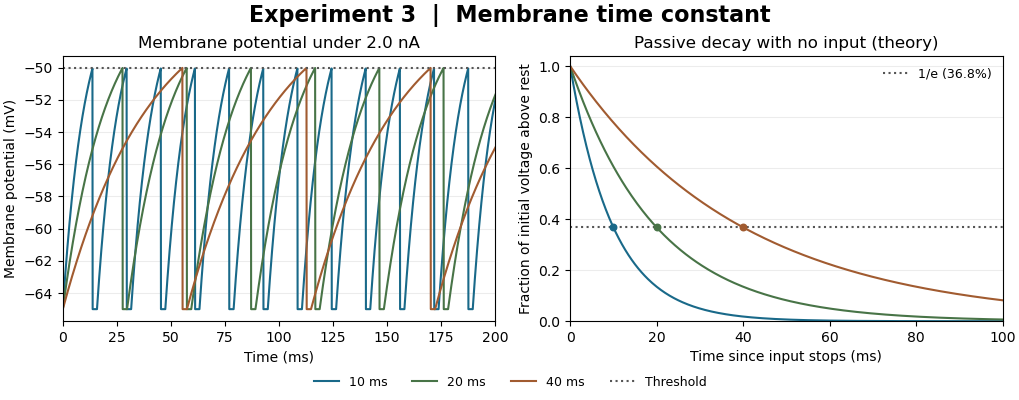

In [9]:
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from lif.model import SimulationParameters, simulate_experiment

baseline = SimulationParameters(
    mode="constant",
    current=2.0,
    threshold=-50.0,
    rest=-65.0,
    resistance=10.0,
    refractory=2.0,
    dt=0.1,
    duration=2000.0,
)
table = [
    "| 参数档位 | 脉冲总数 | 平均发放率 (Hz) | 首发 (ms) | 平均脉冲间隔 (ms) |",
    "| :--- | ---: | ---: | ---: | ---: |",
]
fig, (voltage_ax, decay_ax) = plt.subplots(
    1, 2, figsize=(10.2, 4.0), layout="constrained"
)
fig.suptitle("Experiment 3  |  Membrane time constant", fontsize=16, weight="bold")
decay_time = np.linspace(0, 100, 401)
colors = ("#196989", "#487447", "#a15b30")

for tau_ms, color in zip((10, 20, 40), colors, strict=True):
    parameters = replace(baseline, tau=tau_ms)
    signals = simulate_experiment(parameters)
    spike_times = signals["time_ms"][signals["spikes"].astype(bool)]
    count = spike_times.size
    mean_rate_hz = count * 1000 / parameters.duration
    first_spike = f"{spike_times[0]:.1f}" if count else "—"
    mean_isi = f"{np.diff(spike_times).mean():.1f}" if count > 1 else "—"
    table.append(
        f"| {tau_ms} ms | {count} | {mean_rate_hz:.1f} | {first_spike} | {mean_isi} |"
    )
    voltage_ax.plot(
        signals["time_ms"], signals["voltage"], color=color, label=f"{tau_ms} ms"
    )
    decay_ax.plot(decay_time, np.exp(-decay_time / tau_ms), color=color)
    decay_ax.scatter(tau_ms, np.exp(-1), color=color, s=22, zorder=3)

voltage_ax.axhline(
    baseline.threshold, color="#555555", linestyle=":", label="Threshold"
)
voltage_ax.set(
    title="Membrane potential under 2.0 nA",
    xlabel="Time (ms)",
    ylabel="Membrane potential (mV)",
    xlim=(0, 200),
)
fig.legend(
    *voltage_ax.get_legend_handles_labels(),
    loc="outside lower center",
    ncols=4,
    frameon=False,
    fontsize=9,
)
decay_ax.axhline(np.exp(-1), color="#555555", linestyle=":", label="1/e (36.8%)")
decay_ax.set(
    title="Passive decay with no input (theory)",
    xlabel="Time since input stops (ms)",
    ylabel="Fraction of initial voltage above rest",
    xlim=(0, 100),
    ylim=(0, 1.04),
)
decay_ax.legend(frameon=False, fontsize=9)
for ax in (voltage_ax, decay_ax):
    ax.grid(axis="y", alpha=0.24)

figure_path = project_root / "lif/output/part3/03_membrane_time_constant.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=180, facecolor="white")
display(Markdown("\n".join(table)))
plt.show()

1. **积分和泄漏。** 改变 $\tau_m$ 会改变电位接近稳态和返回静息的速度。
   在相同的恒流与电阻下，三档的发放前稳态电位均为 −45 mV。
2. **轨迹、首发和发放率。** $\tau_m$ 从 10 ms 增至 20 和 40 ms，首发由 13.8 ms
   推迟到 27.7 和 55.4 ms，平均发放率依次为 63.0、33.5、17.0 Hz。电位上升变慢，
   相邻脉冲之间也隔得更久。
3. **膜电路的物理意义。** 膜相当于一个带并联漏电阻 $R$ 的电容 $C$，
   $\tau_m=RC$。停止输入后，$V-V_{\mathrm{rest}}$ 按 $e^{-t/\tau_m}$ 衰减，
   经过一个 $\tau_m$ 剩下初值的约 36.8%。恒流接通后，若尚未到达阈值，经过一个 $\tau_m$ 会走过到稳态电位差的约 63.2%。
   固定 $R=10\,\mathrm{M\Omega}$，这里的三个 $\tau_m$ 等效于 $C=1$、$2$、$4\,\mathrm{nF}$。